# Mi Zai Dau · EDA & App walkthrough (all-HK districts) — English

File: `explore_api_en.ipynb` (English) | Chinese version: `explore_api_zh.ipynb`

**Geographic unit: all ~18 Hong Kong districts (`carparks.district`).** Not limited to Kwun Tong / Sha Tin.

| Part | Content |
|------|---------|
| A | Supabase + live API: car parks, baselines, territory-wide heatmap |
| B | App-aligned shrinkage prediction, district ranking, nearby recommendations |

Requires `.env`: `SUPABASE_URL`, `SUPABASE_ANON_KEY`. For collection use `collect.ipynb`.


## 0 · Setup


In [23]:
from __future__ import annotations

from datetime import datetime, timedelta
from math import asin, cos, radians, sin, sqrt
from pathlib import Path
from zoneinfo import ZoneInfo

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from dotenv import load_dotenv

from parking_db import (
    baselines_frame_to_maps,
    get_read_client,
    load_baselines_dataframe,
    load_carparks_frame,
    load_vacancy_frame,
)

load_dotenv(Path(".env"))

HK_TZ = ZoneInfo("Asia/Hong_Kong")
VACANCY_URL = "https://api.data.gov.hk/v1/carpark-info-vacancy"
WEEKDAY_EN = {0: "Mon", 1: "Tue", 2: "Wed", 3: "Thu", 4: "Fri", 5: "Sat", 6: "Sun"}

BASELINE_PRIOR_K = 3.0
NEARBY_RADIUS_KM = 1.2
NEARBY_RADIUS_FALLBACK_KM = 2.0
NEARBY_DISTANCE_SCORE_POWER = 2.0

plt.rcParams["font.sans-serif"] = [
    "Arial Unicode MS",
    "PingFang HK",
    "Heiti TC",
    "SimHei",
]
plt.rcParams["axes.unicode_minus"] = False

print("setup OK · scope = all HK districts")


setup OK · scope = all HK districts


## A1 · Car parks territory-wide


In [24]:
client = get_read_client()
carparks = load_carparks_frame(client)
carparks["park_id"] = carparks["park_id"].astype(str)

print("Car parks:", len(carparks))
print("Districts:", carparks["district"].nunique())
print(carparks["district"].value_counts().sort_index())


Car parks: 592
Districts: 18
district
中西區     10
九龍城區    24
元朗區     33
北區      31
南區      20
大埔區     28
屯門區     33
東區      34
沙田區     55
油尖旺區    16
深水埗區    36
灣仔區     12
荃灣區     21
葵青區     33
西貢區     44
觀塘區     96
離島區     24
黃大仙區    42
Name: count, dtype: int64


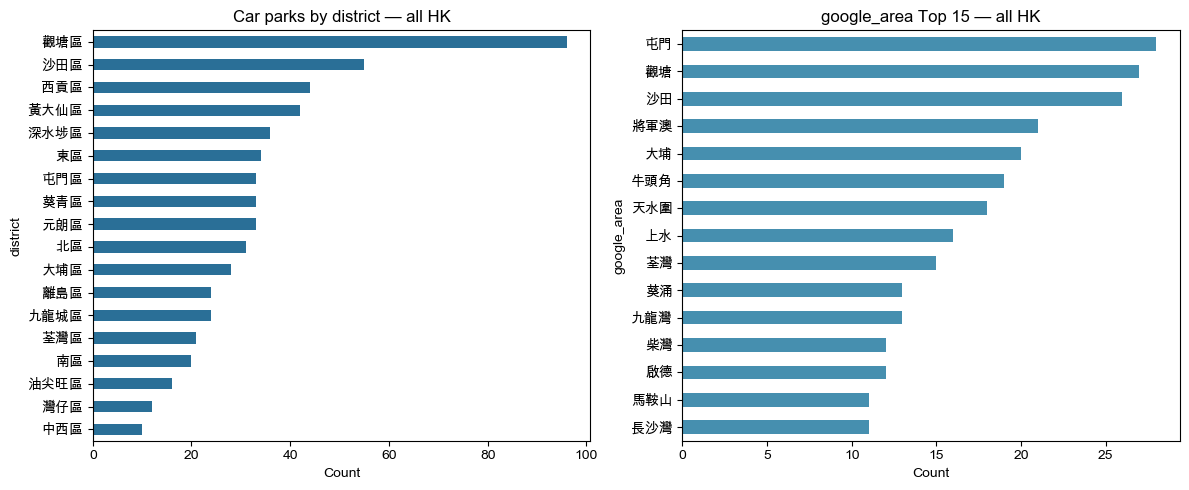

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

carparks["district"].value_counts().sort_values().plot(
    kind="barh", ax=axes[0], color="#2a6f97"
)
axes[0].set_title("Car parks by district — all HK")
axes[0].set_xlabel("Count")

(
    carparks["google_area"]
    .fillna("(missing)")
    .value_counts()
    .head(15)
    .sort_values()
    .plot(kind="barh", ax=axes[1], color="#468faf")
)
axes[1].set_title("google_area Top 15 — all HK")
axes[1].set_xlabel("Count")

plt.tight_layout()
plt.show()


## A2 · Recent `vacancy_records` (all HK)


In [26]:
RECENT_DAYS = 14
since = datetime.now(HK_TZ) - timedelta(days=RECENT_DAYS)

vacancy = load_vacancy_frame(
    client, park_ids=carparks["park_id"].tolist(), since=since
)
vacancy = vacancy[vacancy["vacancy"] >= 0].copy()

print(f"Last {RECENT_DAYS} days · all HK")
print("Rows:", len(vacancy), "| parks:", vacancy["park_id"].nunique())
if vacancy.empty:
    print("Table empty → later steps use baseline + live API")
else:
    print("Range:", vacancy["collected_at"].min(), "→", vacancy["collected_at"].max())
    print(vacancy["district"].value_counts())


Last 14 days · all HK
Rows: 0 | parks: 0
Table empty → later steps use baseline + live API


## A3 · Territory-wide baseline summary


In [27]:
baselines = load_baselines_dataframe(client=client)
if baselines.empty:
    raise RuntimeError("No baselines found: run scripts/build_vacancy_baselines.py first")

print("Rows:", len(baselines), "| parks:", baselines["park_id"].nunique())
print(baselines["n"].describe())

slot_dow = baselines[
    (baselines["half_hour"] >= 0)
    & (baselines["dow"].between(0, 6))
    & (baselines["is_weekend"] == -1)
].copy()

sample_park = slot_dow.groupby("park_id")["n"].sum().idxmax()
sample_row = carparks.loc[carparks["park_id"] == sample_park].iloc[0]
print("Sample park:", sample_park, sample_row["name"], f"({sample_row['district']})")


Rows: 238611 | parks: 511
count    238611.000000
mean        220.658612
std        1302.275812
min           1.000000
25%          62.000000
50%         104.000000
75%         144.000000
max       34911.000000
Name: n, dtype: float64
Sample park: tdc14p1030 小西灣三期停車場 (東區)


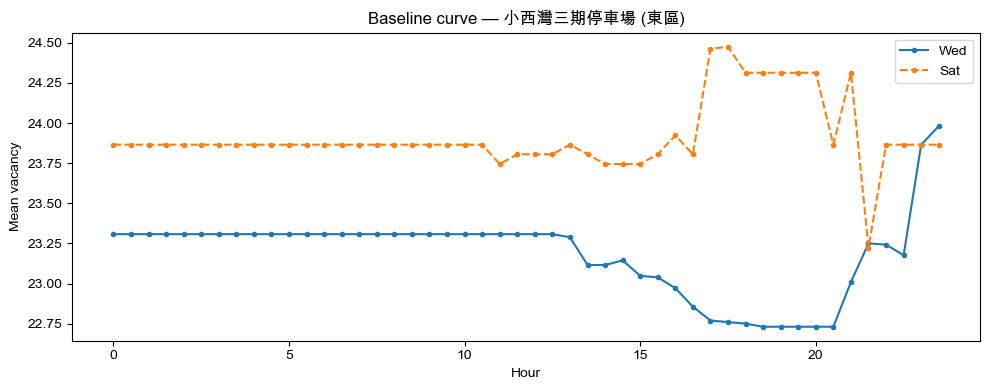

In [28]:
one = slot_dow[slot_dow["park_id"] == sample_park].copy()
one["hour"] = one["half_hour"] / 2.0

fig, ax = plt.subplots(figsize=(10, 4))
for dow, label, ls in [(2, "Wed", "-"), (5, "Sat", "--")]:
    sub = one[one["dow"] == dow].sort_values("half_hour")
    ax.plot(sub["hour"], sub["mean"], ls=ls, marker="o", ms=3, label=label)
ax.set_title(f"Baseline curve — {sample_row['name']} ({sample_row['district']})")
ax.set_xlabel("Hour")
ax.set_ylabel("Mean vacancy")
ax.legend()
plt.tight_layout()
plt.show()


## A4 · All ~18 districts × hour heatmap

Y-axis should list every district (~18 rows), not just two.


Heatmap districts: 18
Names: ['中西區', '油尖旺區', '離島區', '灣仔區', '九龍城區', '南區', '荃灣區', '北區', '沙田區', '西貢區', '大埔區', '元朗區', '觀塘區', '黃大仙區', '葵青區', '屯門區', '東區', '深水埗區']


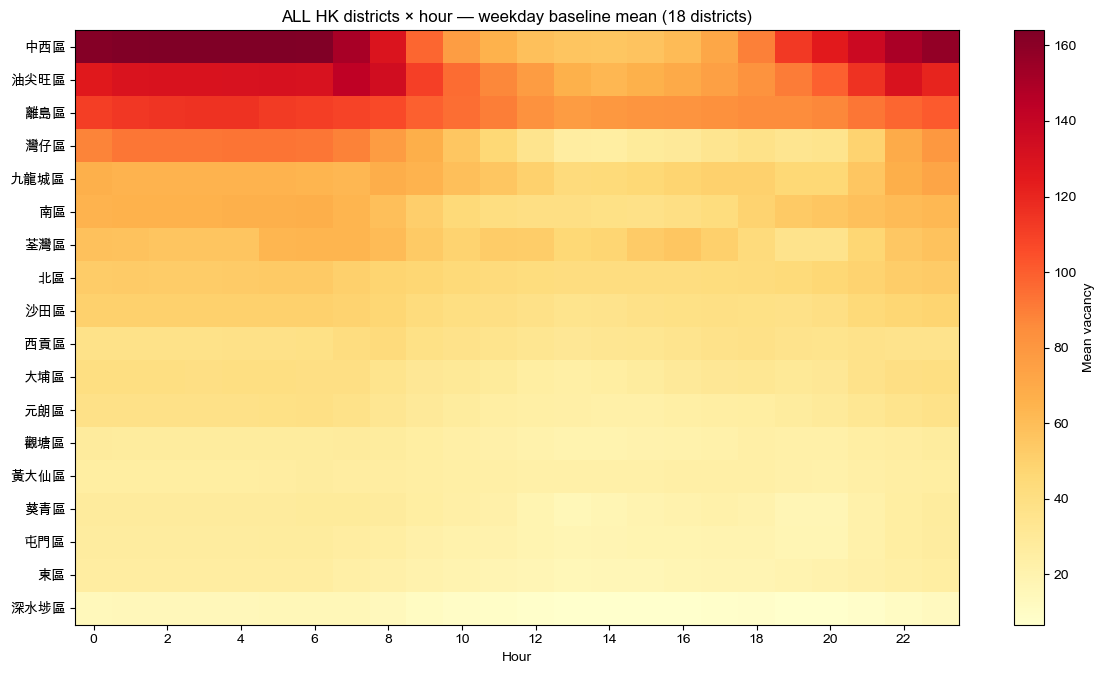

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
district,,,,,,,,,,,,,,,,,,,,,
中西區,161.936038,163.013335,163.444457,163.710563,163.890757,163.967108,163.140029,150.857394,128.570128,97.477096,...,55.402461,56.559511,61.166477,71.722309,89.090642,112.952568,125.032933,136.374030,149.920739,157.705439
油尖旺區,125.398865,129.197176,129.709299,129.878864,130.530191,130.829878,130.513290,143.060945,134.061598,110.407809,...,62.929002,65.773101,69.799793,74.971580,81.958286,90.484719,98.891143,115.303251,129.954666,120.906592
離島區,110.572899,113.073793,114.503257,114.996654,115.137426,112.252508,110.699916,109.018833,106.514810,99.300117,...,79.604577,80.681769,81.380322,83.120427,85.252731,84.881637,87.057123,92.574978,97.542058,101.107861
灣仔區,88.142933,92.373991,92.637144,92.669522,92.732547,92.696661,92.628394,88.841535,76.937502,66.948652,...,25.492858,28.258444,29.488171,33.773845,37.344939,34.014403,35.180221,48.674837,68.982043,79.554206
九龍城區,66.545556,64.873354,64.740809,64.635575,64.641362,64.594529,64.231161,62.837594,67.963547,64.586022,...,43.767903,45.991255,48.002736,50.292594,50.149792,45.687593,45.804154,55.388383,67.036395,71.841366
南區,64.535009,65.232137,65.380514,65.352808,66.505328,66.477017,67.095419,63.946308,59.185555,51.050511,...,38.238159,37.604945,39.334434,42.276987,48.706845,53.970185,55.617247,58.316638,60.790424,62.101712
荃灣區,57.891644,57.544790,56.440076,56.068589,56.014162,63.621844,64.117976,64.129293,60.868067,53.702918,...,47.490621,52.808105,55.802943,50.726641,42.950216,36.005350,35.764476,46.697853,55.131611,57.491622
北區,52.725382,52.765862,52.630923,52.459231,53.354391,53.629706,53.688041,50.357805,48.140846,46.979825,...,41.364870,41.448483,41.430700,41.815532,42.629884,44.048235,46.102226,49.060083,51.607812,52.936914
沙田區,49.900380,49.952498,49.860939,49.801908,49.794740,49.849278,50.003207,48.521106,46.662957,42.449522,...,35.771586,37.643550,38.314273,38.732904,38.087478,37.822476,39.659664,44.406873,46.953261,48.227985


In [29]:
heat = (
    slot_dow.merge(carparks[["park_id", "district"]], on="park_id", how="left")
    .dropna(subset=["district"])
    .assign(hour=lambda d: (d["half_hour"] // 2).astype(int))
)
heat_wd = heat[heat["dow"] < 5]  # weekdays

pivot = (
    heat_wd.groupby(["district", "hour"])["mean"]
    .mean()
    .unstack("hour")
)
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

assert pivot.shape[0] >= 10, f"Too few districts: {pivot.shape[0]} — check baseline/carparks join"
print("Heatmap districts:", pivot.shape[0])
print("Names:", list(pivot.index))

fig, ax = plt.subplots(figsize=(12, max(5.0, 0.38 * len(pivot))))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlOrRd")
ax.set_yticks(range(len(pivot)))
ax.set_yticklabels(pivot.index)
ax.set_xticks(range(0, 24, 2))
ax.set_xticklabels(range(0, 24, 2))
ax.set_xlabel("Hour")
ax.set_title(f"ALL HK districts × hour — weekday baseline mean ({len(pivot)} districts)")
plt.colorbar(im, ax=ax, label="Mean vacancy")
plt.tight_layout()
plt.show()

pivot


## A5 · Live API vs baseline (1 park per district)


Live parks: 504 | now half_hour=36 Fri


,district,name,live,baseline
0,中西區,中山紀念公園,9,8.6
1,九龍城區,Airside,311,326.9
2,元朗區,屏欣停車場,5,16.4
3,北區,祥華A停車場,30,22.8
4,南區,數碼港停車場(一&二),393,366.9
5,大埔區,廣褔停車場,30,23.9
6,屯門區,屯門醫院主座訪客停車場,1,3.8
7,東區,愛東停車場,30,23.9
8,沙田區,科學園停車場 P1,227,223.6
9,油尖旺區,香港故宮文化博物館停車場,1,12.1


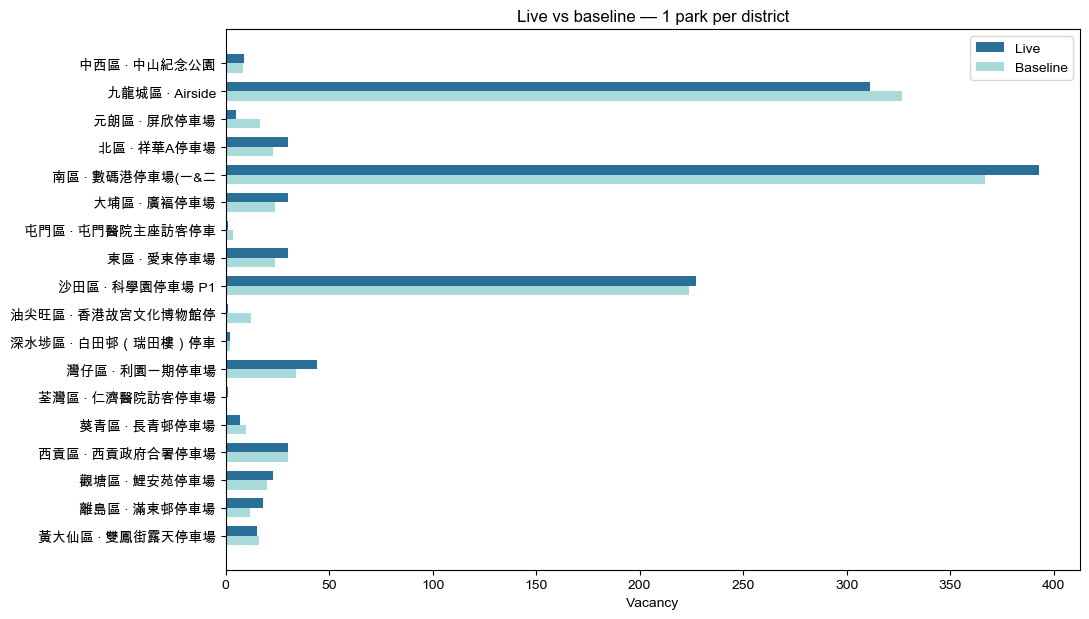

In [30]:
def fetch_live_private_car() -> dict[str, dict]:
    resp = requests.get(
        VACANCY_URL,
        params={"data": "vacancy", "lang": "en", "vehicleTypes": "privateCar"},
        timeout=30,
    )
    resp.raise_for_status()
    out: dict[str, dict] = {}
    for item in resp.json().get("results") or []:
        pid = str(item.get("park_Id") or "")
        private = item.get("privateCar") or []
        if not pid or not private:
            continue
        try:
            vac = int(private[0].get("vacancy"))
        except (TypeError, ValueError):
            continue
        if vac < 0:
            continue
        out[pid] = {"vacancy": vac, "lastupdate": private[0].get("lastupdate")}
    return out


def half_hour_now(ts: datetime | None = None) -> tuple[int, int]:
    ts = ts or datetime.now(HK_TZ)
    return ts.hour * 2 + (1 if ts.minute >= 30 else 0), ts.weekday()


live = fetch_live_private_car()
now_hh, now_dow = half_hour_now()
print("Live parks:", len(live), f"| now half_hour={now_hh} {WEEKDAY_EN[now_dow]}")

simple = (
    slot_dow[(slot_dow["half_hour"] == now_hh) & (slot_dow["dow"] == now_dow)]
    .set_index("park_id")["mean"]
)

rows = []
for district, grp in carparks.groupby("district", sort=True):
    for pid in grp["park_id"]:
        if pid in live and pid in simple.index:
            rows.append(
                {
                    "district": district,
                    "name": grp.loc[grp["park_id"] == pid, "name"].iloc[0],
                    "live": live[pid]["vacancy"],
                    "baseline": round(float(simple.loc[pid]), 1),
                }
            )
            break

compare_df = pd.DataFrame(rows)
display(compare_df)

if not compare_df.empty:
    fig, ax = plt.subplots(figsize=(11, max(4, 0.35 * len(compare_df))))
    y = np.arange(len(compare_df))
    labels = compare_df["district"] + " · " + compare_df["name"].str.slice(0, 10)
    ax.barh(y - 0.17, compare_df["live"], 0.34, label="Live", color="#2a6f97")
    ax.barh(y + 0.17, compare_df["baseline"], 0.34, label="Baseline", color="#a8dadc")
    ax.set_yticks(y)
    ax.set_yticklabels(labels)
    ax.invert_yaxis()
    ax.set_xlabel("Vacancy")
    ax.set_title("Live vs baseline — 1 park per district")
    ax.legend()
    plt.tight_layout()
    plt.show()


## B · App-aligned prediction (shrinkage)

Mirrors `app.py` `_shrink_mean` / `predict_park_vacancy_baseline` (do not `import app`).


In [31]:
def shrink_mean(
    primary: float | None,
    n_primary: int,
    prior: float | None,
    *,
    k: float = BASELINE_PRIOR_K,
) -> float | None:
    if primary is None and prior is None:
        return None
    if primary is None:
        return float(prior) if prior is not None else None
    if prior is None or n_primary <= 0:
        return float(primary)
    w = n_primary / (n_primary + k)
    return float(w * primary + (1.0 - w) * prior)


def predict_park_vacancy_baseline(
    park_id: str, half_hour: int, dow: int, packed: tuple
) -> tuple[float | None, dict]:
    (
        by_slot_dow,
        by_slot_weekend,
        by_slot,
        by_park,
        n_slot_dow,
        n_slot_weekend,
        n_slot,
        n_park,
    ) = packed

    is_weekend = 1 if dow >= 5 else 0
    mean_dow = by_slot_dow.get((park_id, half_hour, dow))
    n_dow = int(n_slot_dow.get((park_id, half_hour, dow), 0))
    mean_we = by_slot_weekend.get((park_id, half_hour, is_weekend))
    n_we = int(n_slot_weekend.get((park_id, half_hour, is_weekend), 0))
    mean_slot = by_slot.get((park_id, half_hour))
    n_s = int(n_slot.get((park_id, half_hour), 0))
    mean_park = by_park.get(park_id)
    n_p = int(n_park.get(park_id, 0))

    prior = mean_we if mean_we is not None else mean_slot
    if prior is None:
        prior = mean_park

    pred = shrink_mean(mean_dow, n_dow, prior)
    source, n_used = "same weekday & slot", n_dow
    if pred is None:
        pred = shrink_mean(mean_we, n_we, mean_slot if mean_slot is not None else mean_park)
        source, n_used = "weekday/weekend slot", n_we
    if pred is None:
        pred = mean_slot if mean_slot is not None else mean_park
        source = "same slot" if mean_slot is not None else "park daily mean"
        n_used = n_s if mean_slot is not None else n_p
    if pred is None:
        return None, {"source": "no data", "n": 0, "confidence": "low"}

    confidence = "high" if n_used >= 6 else ("medium" if n_used >= 2 else "low")
    return float(pred), {"source": source, "n": int(n_used), "confidence": confidence}


packed = baselines_frame_to_maps(baselines)
pred, meta = predict_park_vacancy_baseline(sample_park, now_hh, now_dow, packed)
print(sample_row["name"], "→", None if pred is None else round(pred, 1), meta)


小西灣三期停車場 → 23.9 {'source': 'same weekday & slot', 'n': 104, 'confidence': 'high'}


## B1 · Mean predicted vacancy by district (Fri 19:00)


All HK · Fri 19:00


,district,n_parks,mean_predicted,median_predicted
1,中西區,10,104.5,57.5
2,離島區,17,81.2,23.9
3,油尖旺區,14,78.0,25.7
4,南區,17,47.2,11.8
5,北區,26,41.6,12.4
6,九龍城區,17,39.1,19.0
7,荃灣區,18,38.2,9.7
8,沙田區,49,37.3,23.8
9,西貢區,40,35.0,23.9
10,灣仔區,12,29.1,19.8


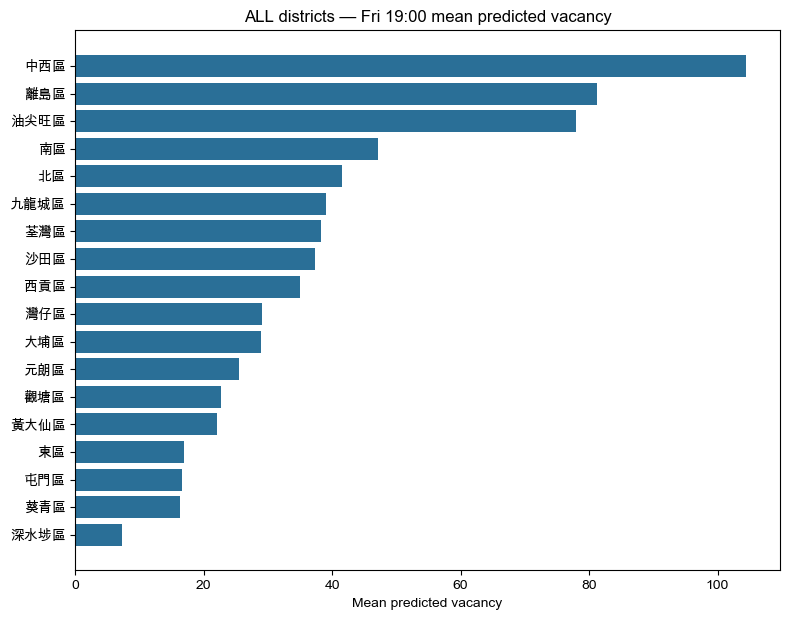

In [32]:
QUERY_HOUR, QUERY_DOW = 19, 4
QUERY_HALF = QUERY_HOUR * 2

district_rows = []
for district, grp in carparks.groupby("district", sort=True):
    preds = [
        p
        for pid in grp["park_id"]
        if (p := predict_park_vacancy_baseline(str(pid), QUERY_HALF, QUERY_DOW, packed)[0])
        is not None
    ]
    if preds:
        district_rows.append(
            {
                "district": district,
                "n_parks": len(preds),
                "mean_predicted": round(float(np.mean(preds)), 1),
                "median_predicted": round(float(np.median(preds)), 1),
            }
        )

district_rank = (
    pd.DataFrame(district_rows)
    .sort_values("mean_predicted", ascending=False)
    .reset_index(drop=True)
)
district_rank.index += 1
print(f"All HK · {WEEKDAY_EN[QUERY_DOW]} {QUERY_HOUR}:00")
display(district_rank)

fig, ax = plt.subplots(figsize=(8, max(4.5, 0.35 * len(district_rank))))
plot_df = district_rank.iloc[::-1]
ax.barh(plot_df["district"], plot_df["mean_predicted"], color="#2a6f97")
ax.set_xlabel("Mean predicted vacancy")
ax.set_title(f"ALL districts — Fri {QUERY_HOUR}:00 mean predicted vacancy")
plt.tight_layout()
plt.show()


## B2 · Nearby recommendations (all-HK park pool · Central demo)


In [33]:
def haversine_km(lat1, lon1, lat2, lon2) -> float:
    r = 6371.0
    p1, p2 = radians(lat1), radians(lat2)
    dp, dl = radians(lat2 - lat1), radians(lon2 - lon1)
    a = sin(dp / 2) ** 2 + cos(p1) * cos(p2) * sin(dl / 2) ** 2
    return float(2 * r * asin(sqrt(a)))


def parks_near(lat, lon, parks, radius_km=NEARBY_RADIUS_KM, fallback_km=NEARBY_RADIUS_FALLBACK_KM):
    work = parks.dropna(subset=["latitude", "longitude"]).copy()
    work["distance_km"] = [
        haversine_km(lat, lon, float(a), float(b))
        for a, b in zip(work["latitude"], work["longitude"])
    ]
    for radius in (radius_km, fallback_km):
        hit = work[work["distance_km"] <= radius].sort_values("distance_km")
        if not hit.empty:
            return hit.reset_index(drop=True), float(radius)
    return work.iloc[0:0].copy(), None


DEMO_LAT, DEMO_LON = 22.2819, 114.1588  # Central
nearby, used_r = parks_near(DEMO_LAT, DEMO_LON, carparks)
print(f"({DEMO_LAT}, {DEMO_LON}) · radius {used_r} km · {len(nearby)} parks")
print("Districts involved:", sorted(nearby["district"].dropna().unique()))

near_rows = []
for _, row in nearby.iterrows():
    pid = str(row["park_id"])
    pred, meta = predict_park_vacancy_baseline(pid, QUERY_HALF, QUERY_DOW, packed)
    if pred is None:
        continue
    dist = float(row["distance_km"])
    near_rows.append(
        {
            "name": row["name"],
            "district": row["district"],
            "distance_km": round(dist, 3),
            "predicted": round(pred, 1),
            "score": round(pred / ((1.0 + dist) ** NEARBY_DISTANCE_SCORE_POWER), 2),
            "live": live.get(pid, {}).get("vacancy"),
            "confidence": meta["confidence"],
        }
    )

nearby_rank = (
    pd.DataFrame(near_rows)
    .sort_values("score", ascending=False)
    .head(8)
    .reset_index(drop=True)
)
nearby_rank.index += 1
display(nearby_rank)


(22.2819, 114.1588) · radius 1.2 km · 5 parks
Districts involved: ['中西區']


,name,district,distance_km,predicted,score,live,confidence
1,天星停車場,中西區,0.194,147.1,103.24,67,high
2,林士街停車場,中西區,0.839,299.7,88.63,90,high
3,港鐵香港站停車場,中西區,0.467,138.7,64.48,75,high
4,大會堂停車場,中西區,0.344,71.0,39.33,15,high
5,金鐘道政府合署,中西區,0.700,44.0,15.22,0,high


## Summary

- Entire notebook is scoped to **all-HK `district`**
- A4 heatmap title includes `ALL HK districts` and the district count (~18)
- B1: mean prediction by district; B2: nearby ranking from the full park pool
- Speech / LLM / fee logic lives only in `app.py`
